# Hello SimOpt!

This script is intended to be an introduction to the world of SimOpt.

The script creates a simple experiment and goes through the process of running, post-processing, post-normalizing, and recording the results.

## Append SimOpt Path

Since the notebook is stored in simopt/notebooks, we need to append the parent simopt directory to the system path to import the necessary modules later on.

In [1]:
import sys
from pathlib import Path

# Take the current directory, find the parent, and add it to the system path
sys.path.append(str(Path.cwd().parent))

## Configuration Parameters

This section defines the core parameters for the demo.

To query model/problem/solver names, run `python scripts/list_directories.py`

In [2]:
# Create an instance of the ProblemSolver class for the given solver and problem
solver_name = "ASTRODF"
problem_name = "CNTNEWS-1"

num_macroreps = 10
num_postreps = 200
num_postreps_init_opt = 200

In [3]:
from simopt.experiment_base import ProblemSolver

myexperiment = ProblemSolver(solver_name, problem_name)
# Run the experiment with a specified number of macro-repetitions
myexperiment.run(n_macroreps=num_macroreps)

In [4]:
# Post-process the results
myexperiment.post_replicate(n_postreps=num_postreps)

In [5]:
# Normalize the results
from simopt.experiment_base import post_normalize

post_normalize(experiments=[myexperiment], n_postreps_init_opt=num_postreps_init_opt)

[PosixPath('/Users/chandulaf/Library/CloudStorage/OneDrive-TheUniversityofMelbourne/Documents/Astro_Trial/simopt/notebooks/experiments/2026-10-21_22-02-50/plots/SOLVER_SET_CNTNEWS-1_mean_prog_curve_unnorm.png')]

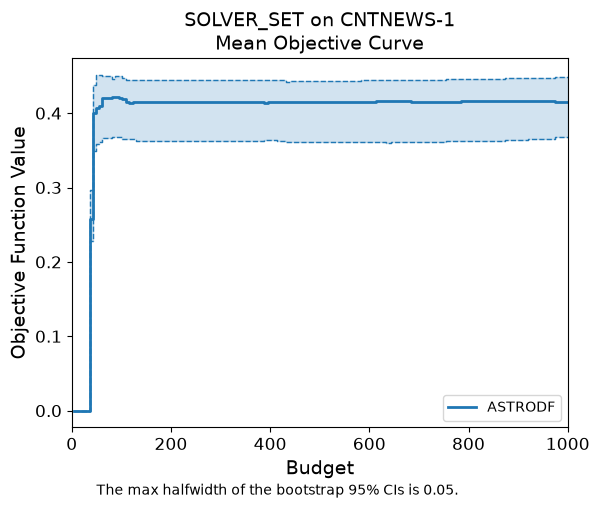

In [6]:
# Record the results and plot the mean progress curve.
from simopt.experiment_base import PlotType, plot_progress_curves

myexperiment.log_experiment_results()
plot_progress_curves(
    experiments=[myexperiment],
    plot_type=PlotType.MEAN,
    normalize=False,
)